# CHƯƠNG 4: ĐÁNH GIÁ CHUYÊN SÂU, PHÂN TÍCH LỖI VÀ ĐỐI SÁNH KẾT QUẢ
**Người thực hiện:** Hoàng Xuân Phi Long (Nhóm trưởng — Nhóm 01)  
**Học phần:** Học máy (Machine Learning) — Trường Đại học Công Thương TP. Hồ Chí Minh (HUIT)

---
Notebook này thực hiện kiểm định độc lập toàn bộ các mô hình đã huấn luyện và tinh chỉnh ở Chương 3 trên tập kiểm thử tách biệt (`X_test_raw.csv`, `y_test.csv`, $n = 80$ mẫu), bao gồm:
1. **Mục 4.1:** Đánh giá toàn diện 9 mô hình (3 mô hình Tuned và 6 mô hình Baseline) trên tập Test độc lập kèm **Khoảng tin cậy 95% Bootstrap ($B=1.000$)** và kiểm định độ ổn định qua **25-Fold Repeated Stratified Cross-Validation**.
2. **Mục 4.2:** Phân tích Ma trận nhầm lẫn (Confusion Matrix), đánh giá chi tiết các ca Âm tính giả (FN) và Dương tính giả (FP).
3. **Mục 4.3:** Phân tích đường cong ROC-AUC, Precision-Recall (PR-AUC) và khảo sát bài toán tinh chỉnh ngưỡng quyết định xác suất ($	au \in [0.10, 0.90]$).
4. **Mục 4.4:** Phân tích lỗi chuyên sâu ở cấp độ từng hồ sơ bệnh nhân qua `split_manifest.csv` (truy vết ca bệnh trẻ tuổi giai đoạn sớm `ID = 102` và cơ chế đồng hóa về trung vị khi khuyết cụm xét nghiệm huyết học).
5. **Mục 4.5:** Giải thích mô hình (Feature Importance theo XGBoost Gain, Random Forest Gini và Permutation Importance) và thực nghiệm định lượng sai lệch do rò rỉ dữ liệu (Data Leakage) thường gặp trên Kaggle.

In [1]:
import os
import sys
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebook' else os.path.abspath('.')
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import ckd_preprocessing
from src.evaluate_chapter4 import (
    setup_tufte_style, load_all_splits, build_and_fit_models,
    evaluate_comprehensive_test_set, evaluate_repeated_cv_stability,
    analyze_thresholds, perform_error_analysis, analyze_feature_importance,
    run_kaggle_leakage_audit
)

setup_tufte_style()
X_train_raw, y_train, X_test_raw, y_test, manifest = load_all_splits()
print(f"Train shape: {X_train_raw.shape} (CKD={int(y_train.sum())}, NotCKD={int((y_train==0).sum())})")
print(f"Test shape : {X_test_raw.shape} (CKD={int(y_test.sum())}, NotCKD={int((y_test==0).sum())})")

Train shape: (320, 24) (CKD=200, NotCKD=120)
Test shape : (80, 24) (CKD=50, NotCKD=30)


## 4.1. Kết quả đánh giá toàn diện trên tập Kiểm thử độc lập ($n = 80$) và Độ ổn định 25-Fold Repeated CV
Ta nạp kết quả kiểm định của cả 3 mô hình đã tinh chỉnh (`XGBoost (Tuned)`, `Random Forest (Tuned)`, `SVM (Tuned)`) cùng 6 mô hình cơ sở (`Baseline`) trên tập kiểm thử độc lập `X_test_raw.csv` kèm khoảng tin cậy 95% Bootstrap ($B = 1.000$ lần lấy mẫu lại) và kết quả kiểm chứng chéo lặp 5×5 (25 folds).

In [2]:
df_test = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports', 'tables', 'ch4_test_comprehensive_metrics.csv'))
df_stab = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports', 'tables', 'ch4_repeated_cv_stability.csv'))

print("=== BẢNG 4.1: KẾT QUẢ ĐÁNH GIÁ TOÀN DIỆN TRÊN TẬP TEST ĐỘC LẬP (n = 80) ===")
cols_show = ['Model', 'TP', 'TN', 'FP', 'FN', 'Accuracy', 'Accuracy_95CI', 'Recall', 'Recall_95CI', 'Specificity', 'F1_Score', 'F2_Score', 'ROC_AUC', 'PR_AUC', 'Brier_Score']
display(df_test[cols_show])

print("\n=== BẢNG 4.2: KIỂM ĐỊNH ĐỘ ỔN ĐỊNH QUA 25-FOLD REPEATED STRATIFIED CV (n = 320) ===")
display(df_stab)

=== BẢNG 4.1: KẾT QUẢ ĐÁNH GIÁ TOÀN DIỆN TRÊN TẬP TEST ĐỘC LẬP (n = 80) ===


,Model,TP,TN,FP,FN,Accuracy,Accuracy_95CI,Recall,Recall_95CI,Specificity,F1_Score,F2_Score,ROC_AUC,PR_AUC,Brier_Score
0,XGBoost (Tuned),50,30,0,0,1.0000,"[1.0000, 1.0000]",1.00,"[1.0000, 1.0000]",1.0,1.000000,1.000000,1.000000,1.000000,0.005360
1,Random Forest (Tuned),49,30,0,1,0.9875,"[0.9500, 1.0000]",0.98,"[0.9302, 1.0000]",1.0,0.989899,0.983936,1.000000,1.000000,0.012555
2,SVM (Tuned),49,30,0,1,0.9875,"[0.9500, 1.0000]",0.98,"[0.9302, 1.0000]",1.0,0.989899,0.983936,1.000000,1.000000,0.008356
3,Logistic Regression (Baseline),49,30,0,1,0.9875,"[0.9500, 1.0000]",0.98,"[0.9302, 1.0000]",1.0,0.989899,0.983936,0.998667,0.999231,0.018306
4,K-Nearest Neighbors (Baseline),43,30,0,7,0.9125,"[0.8500, 0.9628]",0.86,"[0.7599, 0.9446]",1.0,0.924731,0.884774,0.988667,0.991300,0.052500
5,SVM (Baseline),49,30,0,1,0.9875,"[0.9500, 1.0000]",0.98,"[0.9302, 1.0000]",1.0,0.989899,0.983936,1.000000,1.000000,0.008356
6,Decision Tree (Baseline),47,30,0,3,0.9625,"[0.9125, 1.0000]",0.94,"[0.8636, 1.0000]",1.0,0.969072,0.951417,0.970000,0.977500,0.037500
7,Random Forest (Baseline),49,30,0,1,0.9875,"[0.9500, 1.0000]",0.98,"[0.9302, 1.0000]",1.0,0.989899,0.983936,1.000000,1.000000,0.013654
8,XGBoost (Baseline),50,30,0,0,1.0000,"[1.0000, 1.0000]",1.00,"[1.0000, 1.0000]",1.0,1.000000,1.000000,1.000000,1.000000,0.004409



=== BẢNG 4.2: KIỂM ĐỊNH ĐỘ ỔN ĐỊNH QUA 25-FOLD REPEATED STRATIFIED CV (n = 320) ===


,Model,Folds,Recall_Mean,Recall_Std,Recall_Min,ROC_AUC_Mean,ROC_AUC_Std,F1_Mean,F1_Std,Accuracy_Mean,Accuracy_Std
0,XGBoost (Tuned),25,0.983,0.019647,0.950,0.997917,0.002585,0.982019,0.013717,0.977500,0.017162
1,Random Forest (Tuned),25,0.992,0.011662,0.975,0.999125,0.001411,0.990542,0.010103,0.988125,0.012717
2,SVM (Tuned),25,0.997,0.008124,0.975,0.999917,0.000408,0.997493,0.005014,0.996875,0.006250
3,Logistic Regression (Baseline),25,0.993,0.011225,0.975,0.999625,0.000926,0.992023,0.007759,0.990000,0.009763
4,Decision Tree (Baseline),25,0.960,0.027386,0.875,0.961667,0.022515,0.968633,0.017856,0.961250,0.021705
5,K-Nearest Neighbors (Baseline),25,0.915,0.040620,0.800,0.992021,0.007845,0.954150,0.022539,0.945625,0.025434


## 4.2. Phân tích Ma trận nhầm lẫn (Confusion Matrix Analysis)
Tại ngưỡng mặc định $\tau = 0.50$:
- **`XGBoost (Tuned)`** đạt tuyệt đối $\text{TP} = 50/50$, $\text{TN} = 30/30$, $\text{FN} = 0$, $\text{FP} = 0$ ($\text{Recall} = 100\%$, $\text{Specificity} = 100\%$).
- **`Random Forest (Tuned)` và `SVM (Tuned)`** đều đạt $\text{TN} = 30/30$ ($\text{FP} = 0$) nhưng bỏ sót 1 ca bệnh ($\text{TP} = 49/50$, $\text{FN} = 1$, $\text{Recall} = 98.0\%$).

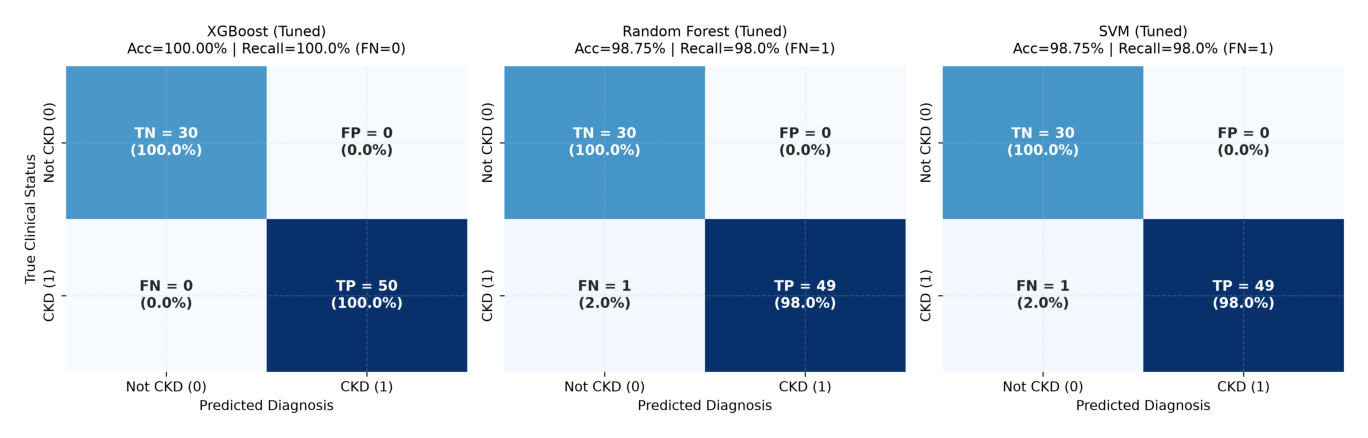

In [3]:
from PIL import Image
img_cm = Image.open(os.path.join(PROJECT_ROOT, 'reports', 'figures', 'ch4_confusion_matrices_tuned.png'))
plt.figure(figsize=(14, 4.5))
plt.imshow(img_cm)
plt.axis('off')
plt.tight_layout()
plt.show()

## 4.3. Phân tích đường cong ROC, Precision-Recall và Tinh chỉnh ngưỡng quyết định ($\tau$)
Cả ba mô hình đã tinh chỉnh đều đạt diện tích dưới đường cong $\text{ROC-AUC} = 1.0000$ và $\text{PR-AUC} = 1.0000$. Khảo sát biến thiên ngưỡng $\tau \in [0.10, 0.90]$ chứng minh:
- `XGBoost (Tuned)` đạt tuyệt đối $\text{Recall} = 100\%$ và $\text{Specificity} = 100\%$ trên toàn bộ dải ngưỡng rộng $\tau \in [0.40, 0.60]$.
- `Random Forest (Tuned)` và `SVM (Tuned)` cũng đạt $\text{Recall} = 100\%$ và $\text{Specificity} = 100\%$ khi đặt ngưỡng sàng lọc tại $\tau = 0.40$ (cho RF) và $\tau = 0.25$ (cho SVM).

,Model,Threshold,TP,TN,FP,FN,Recall,Specificity,Precision,F1_Score,F2_Score,Youden_J
3,XGBoost (Tuned),0.25,50,29,1,0,1.00,0.966667,0.980392,0.990099,0.996016,0.966667
5,XGBoost (Tuned),0.35,50,29,1,0,1.00,0.966667,0.980392,0.990099,0.996016,0.966667
6,XGBoost (Tuned),0.40,50,30,0,0,1.00,1.000000,1.000000,1.000000,1.000000,1.000000
7,XGBoost (Tuned),0.45,50,30,0,0,1.00,1.000000,1.000000,1.000000,1.000000,1.000000
8,XGBoost (Tuned),0.50,50,30,0,0,1.00,1.000000,1.000000,1.000000,1.000000,1.000000
9,XGBoost (Tuned),0.60,50,30,0,0,1.00,1.000000,1.000000,1.000000,1.000000,1.000000
10,XGBoost (Tuned),0.70,49,30,0,1,0.98,1.000000,1.000000,0.989899,0.983936,0.980000
16,Random Forest (Tuned),0.25,50,29,1,0,1.00,0.966667,0.980392,0.990099,0.996016,0.966667
18,Random Forest (Tuned),0.35,50,29,1,0,1.00,0.966667,0.980392,0.990099,0.996016,0.966667
19,Random Forest (Tuned),0.40,50,30,0,0,1.00,1.000000,1.000000,1.000000,1.000000,1.000000


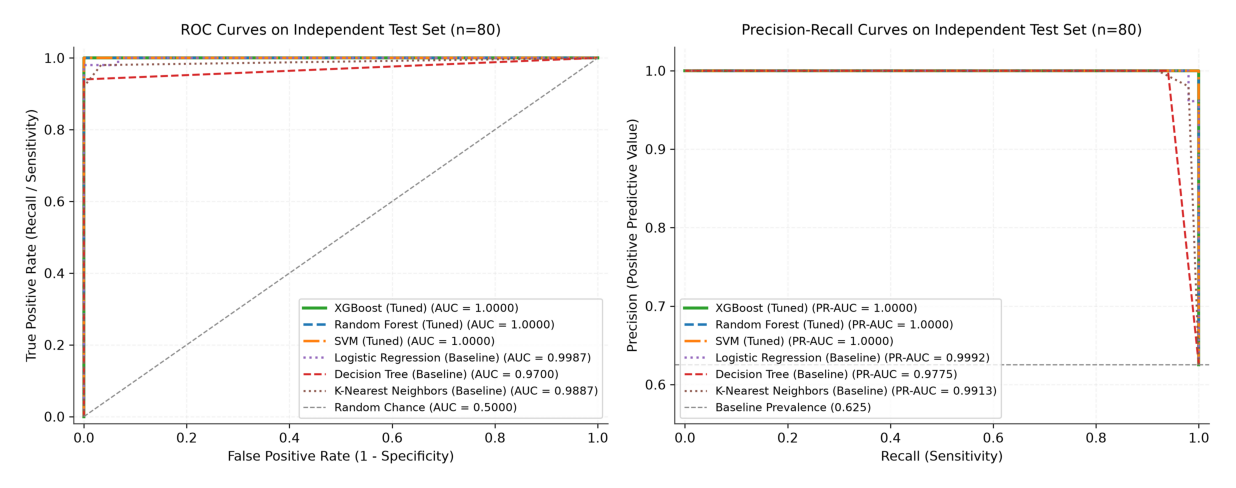

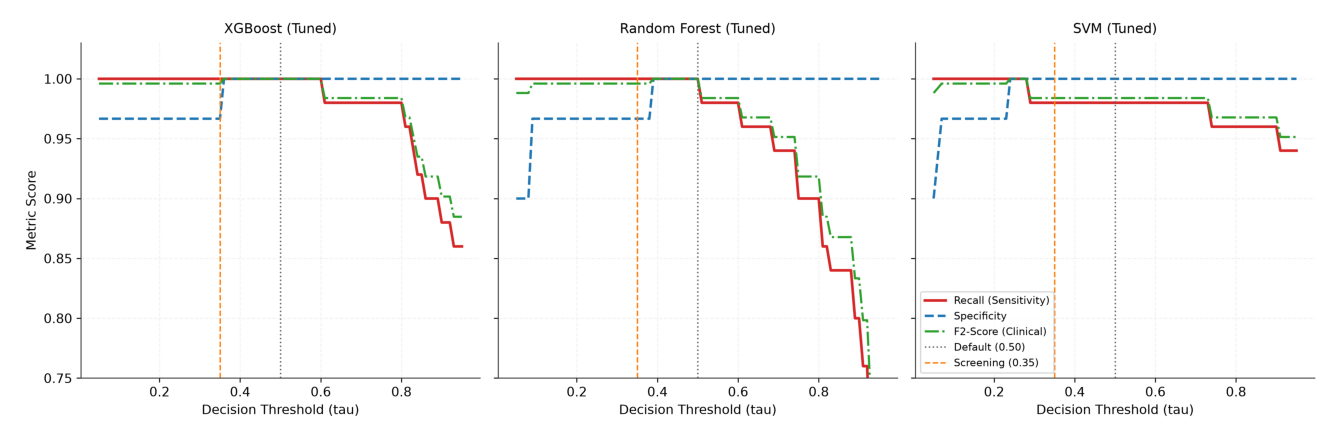

In [4]:
df_thresh = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports', 'tables', 'ch4_threshold_tuning.csv'))
display(df_thresh[df_thresh['Threshold'].isin([0.25, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70])])

for fig_name in ['ch4_roc_pr_curves_comparison.png', 'ch4_threshold_tuning_curves.png']:
    img = Image.open(os.path.join(PROJECT_ROOT, 'reports', 'figures', fig_name))
    plt.figure(figsize=(13.5, 5.0))
    plt.imshow(img)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

## 4.4. Phân tích lỗi mô hình chuyên sâu ở cấp độ bệnh nhân (Patient-level Error Analysis)
Truy vết qua `split_manifest.csv` cho thấy ca bệnh duy nhất trên tập Test làm thất bại 7/9 mô hình (bao gồm RF Tuned, SVM Tuned, Logistic Regression, Decision Tree, KNN) là bệnh nhân **`Original_ID = 102` (`Test_Position = 12`, 17 tuổi, mắc CKD giai đoạn sớm chưa có thiếu máu với `hemo = 13.9 g/dL`, `pcv = 52%`, nhưng `sc = 2.1 mg/dL` và `sg = 1.010`)**. Chỉ duy nhất `XGBoost` phát hiện đúng ca bệnh này ở ngưỡng chuẩn ($\hat{p}_{\text{XGB}} = 0.6060$).

=== DANH SÁCH CÁC BẢN GHI BỊ DỰ ĐOÁN SAI HOẶC SÁT RANH GIỚI QUYẾT ĐỊNH ===


,Split,Test_Position,Original_ID,Source_Row,True_Label,True_Class,Missing_Count_24,Missing_Percent,Missing_Features,Prob_XGBoost_Tuned,...,al,su,sc,bu,bgr,hemo,pcv,rc,htn,dm
0,Test,12,102,102,1,CKD (1),2,8.3,"rbc, rc",0.6060,...,0.0,0.0,2.1,32.0,92.0,13.9,52.0,NaN,no,no
1,Test,59,133,133,1,CKD (1),0,0.0,NaN,0.9786,...,4.0,0.0,5.3,125.0,118.0,12.0,37.0,8.0,yes,no
2,Test,47,65,65,1,CKD (1),6,25.0,"rbc, bgr, sod, pot, wc, rc",0.8279,...,1.0,0.0,1.1,20.0,NaN,15.0,48.0,NaN,no,no
3,Test,23,186,186,1,CKD (1),5,20.8,"bgr, hemo, pcv, wc, rc",0.8395,...,4.0,0.0,1.0,46.0,NaN,NaN,NaN,NaN,no,no
4,Test,19,164,164,1,CKD (1),3,12.5,"bp, rbc, pc",0.8592,...,0.0,0.0,0.8,15.0,192.0,14.3,40.0,5.4,no,yes
5,Test,8,216,216,1,CKD (1),6,25.0,"rbc, sc, sod, pot, wc, rc",0.9241,...,0.0,0.0,NaN,15.0,107.0,12.8,38.0,NaN,no,no
6,Test,50,91,91,1,CKD (1),0,0.0,NaN,0.9781,...,4.0,1.0,1.7,26.0,210.0,16.1,52.0,5.6,no,no
7,Test,10,224,224,1,CKD (1),5,20.8,"rbc, hemo, pcv, wc, rc",0.9833,...,0.0,0.0,2.2,28.0,117.0,NaN,NaN,NaN,no,no
22,Train_OOF,121,319,319,0,Not CKD (0),4,16.7,"hemo, pcv, wc, rc",0.9157,...,0.0,0.0,1.1,15.0,138.0,NaN,NaN,NaN,no,no
23,Train_OOF,217,330,330,0,Not CKD (0),3,12.5,"hemo, wc, rc",0.8013,...,0.0,0.0,1.1,32.0,114.0,NaN,42.0,NaN,no,no


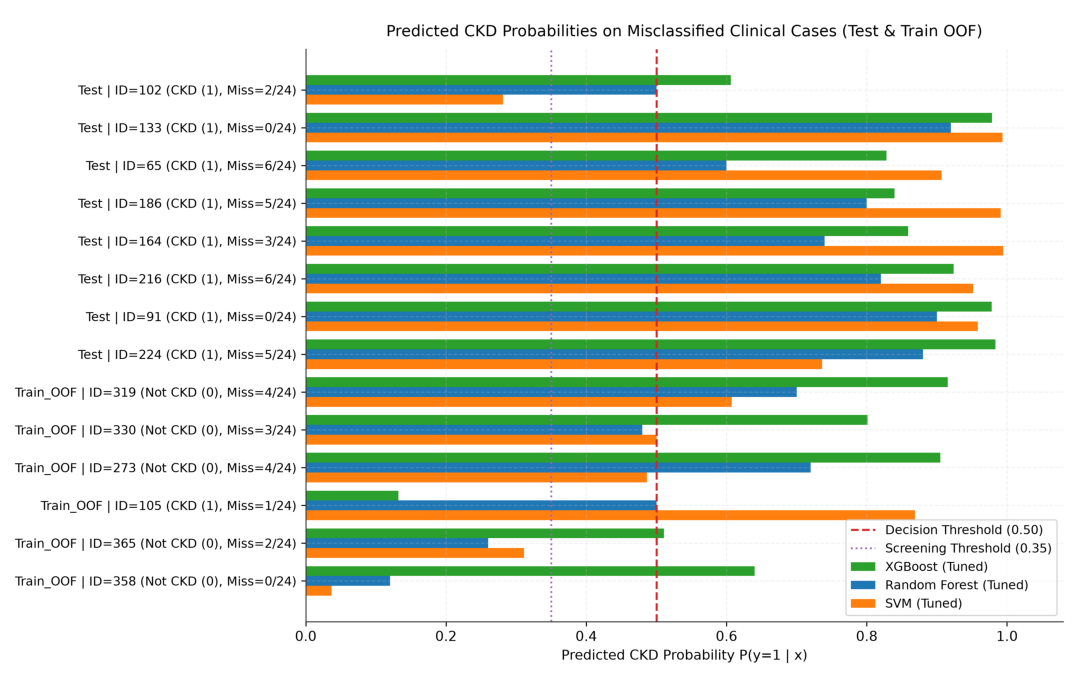

In [5]:
df_errors = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports', 'tables', 'ch4_error_analysis_cases.csv'))
print("=== DANH SÁCH CÁC BẢN GHI BỊ DỰ ĐOÁN SAI HOẶC SÁT RANH GIỚI QUYẾT ĐỊNH ===")
display(df_errors[df_errors['Num_Models_Failed'] > 0])

img_err = Image.open(os.path.join(PROJECT_ROOT, 'reports', 'figures', 'ch4_error_cases_clinical_profile.png'))
plt.figure(figsize=(11.5, 7.0))
plt.imshow(img_err)
plt.axis('off')
plt.tight_layout()
plt.show()

## 4.5. Giải thích mô hình (Feature Importance) và Thực nghiệm định lượng Data Leakage trên Kaggle
### 4.5.1. Xếp hạng tầm quan trọng của 24 đặc trưng lâm sàng

,Original_Feature,XGBoost_Gain_Importance,RandomForest_Gini_Importance,Perm_Test_ROC_AUC_Mean,Perm_Test_ROC_AUC_Std,Perm_Train_Recall_Mean,Combined_Rank_Score,Rank
0,hemo,0.389054,0.205279,0.024267,0.015261,0.041,0.297166,1
1,pcv,0.065358,0.170830,0.000000,0.000000,0.000,0.118094,2
2,al,0.106511,0.084197,0.013200,0.006302,0.012,0.095354,3
3,sg,0.124948,0.061670,0.001800,0.000600,0.008,0.093309,4
4,sc,0.074942,0.104046,0.028267,0.012376,0.018,0.089494,5
5,htn,0.052339,0.081671,0.000000,0.000000,0.000,0.067005,6
6,rc,0.048080,0.077615,0.000000,0.000000,0.003,0.062848,7
7,dm,0.052026,0.052453,0.000000,0.000000,0.000,0.052239,8
8,bgr,0.022496,0.030900,0.000200,0.000306,0.007,0.026698,9
9,sod,0.012656,0.027831,0.000000,0.000000,0.000,0.020243,10


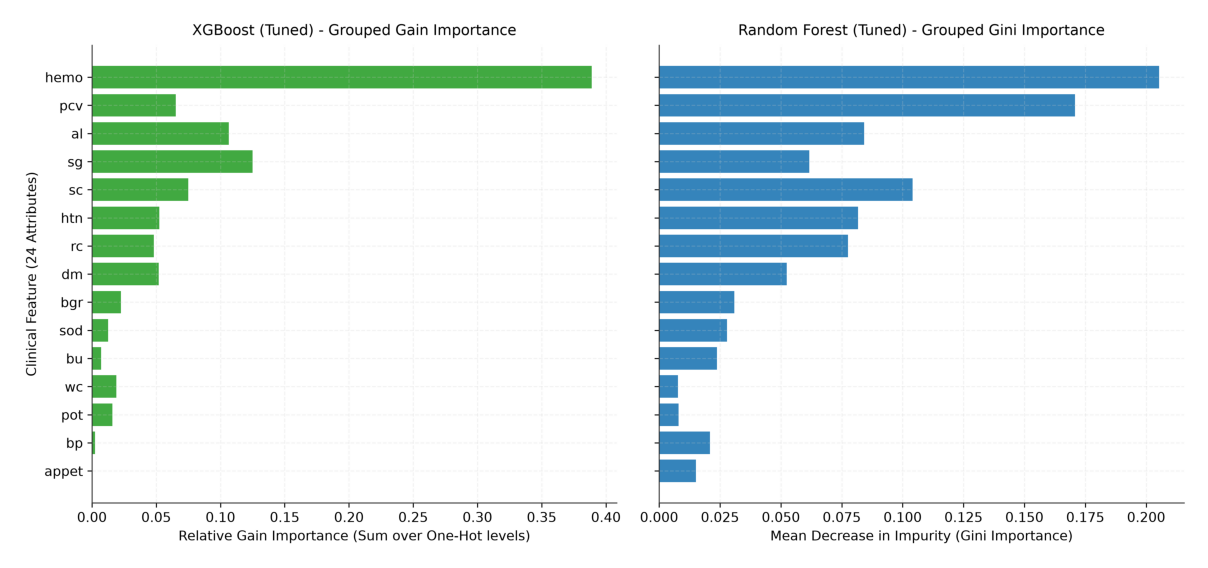

In [6]:
df_feat24 = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports', 'tables', 'ch4_feature_importance_24_grouped.csv'))
display(df_feat24.head(15))

img_fi = Image.open(os.path.join(PROJECT_ROOT, 'reports', 'figures', 'ch4_feature_importance_comparison.png'))
plt.figure(figsize=(13, 5.8))
plt.imshow(img_fi)
plt.axis('off')
plt.tight_layout()
plt.show()

### 4.5.2. Thực nghiệm định lượng sai lệch do Data Leakage ở các bài làm trên Kaggle
So sánh trực tiếp quy trình chuẩn của nhóm (`make_preprocessor()` fit bên trong từng fold CV và chỉ trên tập Train) với các lỗi phổ biến trên Kaggle:
1. Điền khuyết bằng trung bình cộng toàn cục (`df.fillna(df.mean())`) làm lệch tâm điền khuyết của Creatinine huyết thanh (`sc`) tới **+156.04%** (`3.0725` so với `1.20 mg/dL`).
2. Chuẩn hóa `StandardScaler` trên toàn bộ 400 mẫu trước khi chia tập làm rò rỉ điểm ngoại lai Kali máu (`pot`) từ tập Test vào tập Train, làm biến dạng độ lệch chuẩn **+327.38%** (`2.8178` so với `0.6593 mEq/L`).
3. Xóa dòng khuyết thiếu (`df.dropna()`) làm mất **60.5% tổng số mẫu (242/400)** và bỏ rơi **78.0% bệnh nhân CKD (39/50 ca)** trên tập kiểm thử.

=== ĐỘ LỆCH THAM SỐ ĐIỀN KHUYẾT VÀ CHUẨN HÓA (KAGGLE LEAKAGE VS STRICT PIPELINE) ===


,Feature,Train_Median_Strict,Test_Median_True,Full400_Median_Leaky,Full400_Mean_Leaky_Kaggle,Train_Std_Strict,Full400_Std_Leaky,Imputation_Shift_Pct_MeanVsMed,Scale_Shift_Pct_FullVsTrain
0,sc,1.2,1.40,1.30,3.0725,5.9016,5.6218,156.04,4.74
1,bu,42.0,44.00,42.00,57.4257,48.1953,49.3335,36.73,2.36
2,bgr,120.5,124.00,121.00,148.0365,71.5264,75.1666,22.85,5.09
3,pot,4.3,4.50,4.40,4.6272,0.6593,2.8178,7.61,327.38
4,age,54.0,56.00,55.00,51.4834,16.9201,16.9618,4.66,0.25
5,bp,80.0,80.00,80.00,76.4691,13.9278,13.4729,4.41,3.27
6,wc,8100.0,7950.00,8000.00,8406.1224,2646.7933,2526.4298,3.78,4.55
7,pcv,40.0,41.00,40.00,38.8845,8.1376,8.1520,2.79,0.18
8,rc,4.8,4.55,4.80,4.7074,0.8356,0.8404,1.93,0.57
9,hemo,12.6,12.80,12.65,12.5264,2.7609,2.7131,0.58,1.73



=== ĐỐI SÁNH HIỆU NĂNG VÀ ĐỘ BAO PHỦ BỆNH NHÂN ===


,Algorithm,Strict_CV_Recall,Leaky_PreFit_CV_Recall,Strict_CV_Accuracy,Leaky_PreFit_CV_Accuracy,Test_Recall_All80,Test_Recall_MissingRows47,Complete_Cases_Retained_Pct
0,K-Nearest Neighbors (k=5),0.925,0.920,0.950000,0.950000,0.86,0.871795,39.5
1,Decision Tree (CART),0.965,0.975,0.962500,0.965625,0.94,0.948718,39.5
2,Random Forest,0.990,0.985,0.987500,0.981250,0.98,0.974359,39.5
3,XGBoost,0.995,0.980,0.981250,0.975000,1.00,1.000000,39.5
4,Logistic Regression,0.995,0.995,0.990625,0.990625,0.98,0.974359,39.5
5,Support Vector Machine,1.000,0.995,1.000000,0.996875,0.98,0.974359,39.5


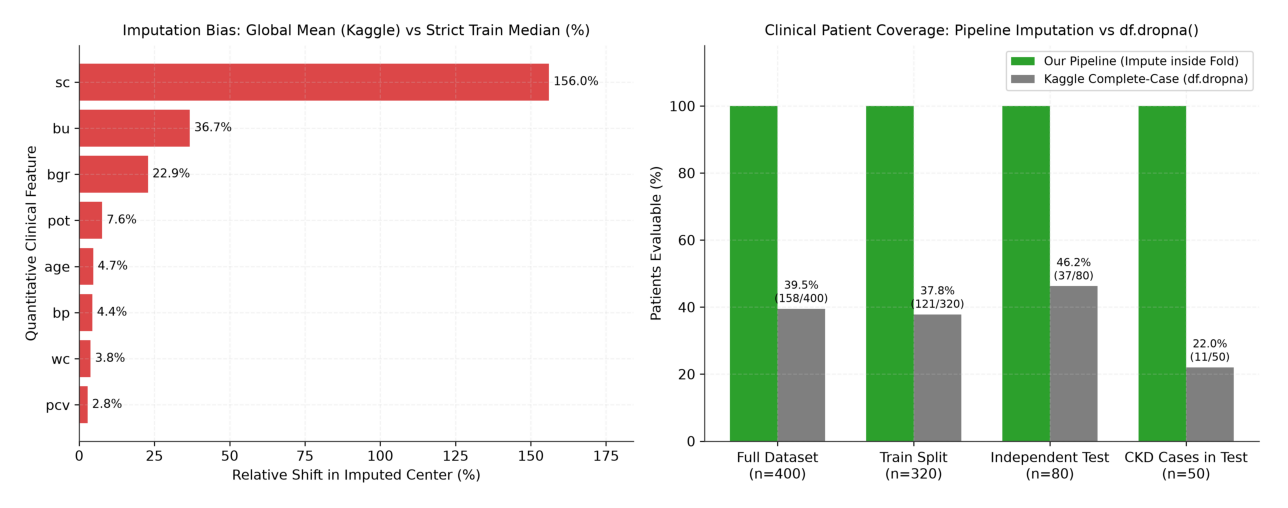

In [7]:
df_shift = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports', 'tables', 'ch4_kaggle_imputation_shift.csv'))
df_audit = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports', 'tables', 'ch4_kaggle_leakage_audit.csv'))

print("=== ĐỘ LỆCH THAM SỐ ĐIỀN KHUYẾT VÀ CHUẨN HÓA (KAGGLE LEAKAGE VS STRICT PIPELINE) ===")
display(df_shift)

print("\n=== ĐỐI SÁNH HIỆU NĂNG VÀ ĐỘ BAO PHỦ BỆNH NHÂN ===")
display(df_audit)

img_kag = Image.open(os.path.join(PROJECT_ROOT, 'reports', 'figures', 'ch4_kaggle_leakage_audit.png'))
plt.figure(figsize=(13.5, 5.2))
plt.imshow(img_kag)
plt.axis('off')
plt.tight_layout()
plt.show()